## **Module 3: Computational Drug Discovery Project**

Team members: Jenny Mejia & Jenna Nguyen

## Project Goal:

You are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Your overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Your project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.
  
The below sections should be addressed in your Project Report as a Jupyter notebook, based on Module3_Project_Template.ipynb. All groups submit a Project Report, only those in the Sullivan Company have Oral Presentations (**all due 11/17**).

## Disease Background: 
Provide a brief (<200 word) background of obesity, available treatments, and especially why improved treatments are needed. Your answers may include for example: 
Prevalence & incidence, Symptoms, Diagnosis, Standard of care treatments (& reimbursement), Disease progression & prognosis, Biological mechanisms (anatomy, organ physiology, cell & molecular physiology), Clinical Trials/next-gen therapies.

Please provide citations and/or hyperlinks to where you obtained information (including AI) for each of the bullet points.

## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 
a)	Adapt your previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data. 
b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.
c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

Please see https://github.com/pypa/pip/issues/5599 for advice on fixing the underlying issue.
To avoid this problem you can invoke Python with '-m pip' instead of running pip directly.


Requirement already satisfied: numpy in c:\Users\jenny\anaconda3\envs\BME2315\Lib\site-packages (2.5.3)

Requirement already satisfied: matplotlib in c:\Users\jenny\anaconda3\envs\BME2315\Lib\site-packages (3.11.2)

Requirement already satisfied: scipy in c:\Users\jenny\anaconda3\envs\BME2315\Lib\site-packages (1.18.1)

Requirement already satisfied: contourpy>=1.0.1 in c:\Users\jenny\anaconda3\envs\BME2315\Lib\site-packages (from matplotlib) (1.4.0)

Requirement already satisfied: cycler>=0.10 in c:\Users\jenny\anaconda3\envs\BME2315\Lib\site-packages (from matplotlib) (0.12.1)

... (635 outputs left out)

DEPRECATION: Unexpected import of 'PIL.ImageOps' after pip install started. pip 26.3 will enforce this behaviour change. Discussion can be found at https://github.com/pypa/pip/issues/13842 (c:\Users\jenny\anaconda3\envs\BME2315\Lib\site-packages\PIL\GifImagePlugin.py:36)


DEPRECATION: Unexpected import of 'PIL.JpegImagePlugin' after pip install started. pip 26.3 will enforce this behaviour change. Discussion can be found at https://github.com/pypa/pip/issues/13842 (c:\Users\jenny\anaconda3\envs\BME2315\Lib\site-packages\PIL\Image.py:453)


DEPRECATION: Unexpected import of 'PIL.JpegPresets' after pip install started. pip 26.3 will enforce this behaviour change. Discussion can be found at https://github.com/pypa/pip/issues/13842 (c:\Users\jenny\anaconda3\envs\BME2315\Lib\site-packages\PIL\JpegImagePlugin.py:51)


DEPRECATION: Unexpected import of 'PIL.PpmImagePlugin' after pip install started. pip 26.3 will enforce this behaviour change. Discussion can be found at https://github.com/pypa/pip/issues/13842 (c:\Users\jenny\anaconda3\envs\BME2315\Lib\site-packages\PIL\Image.py:459)


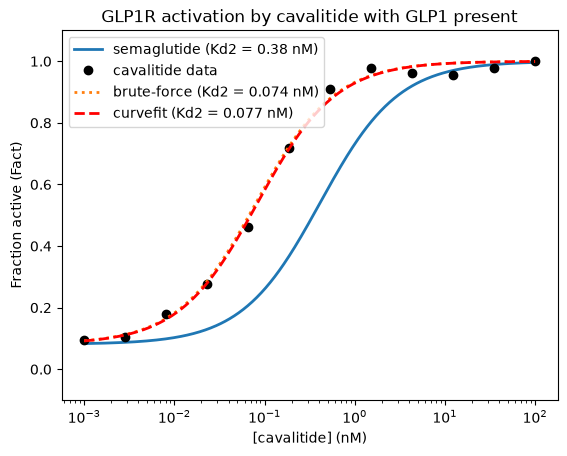

In [1]:
import pip
pip.main(['install', 'numpy', 'matplotlib', 'scipy'])
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Parameters [nM]
Kd1 = 0.17 # L1, GLP1
Kd2 = 0.38 # default 0.38 L2, semaglutide (to fit)
L1 = 0.015 # [nM] GLP1 (fasting)
L2 = np.logspace(-3, 2, 500) # [nM] semaglutide or cavalitide

# Load the data
data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)
L2_loaded, Fact_loaded = data[:, 0], data[:, 1]

# Approach 1: Brute force optimization of Kd2: try many candidate values in a for loop
Kd2_candidates = np.logspace(-3, 2, 100) # [nM]
SSE_brute = np.inf
for Kd2_try in Kd2_candidates:
    # Sum of squared errors between the data and the model for this candidate
    SSE = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_try))**2)
    if SSE < SSE_brute:
        SSE_brute = SSE
        Kd2_brute = Kd2_try
print(f"Brute-force Kd2 = {Kd2_brute:.3f} nM (SSE = {SSE_brute:.4f})")

# Approach 2: Python curvefit of Kd2: related to steepest descent method
popt, pcov = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
                       L2_loaded, Fact_loaded, p0=[0.1], bounds=(0, np.inf))
Kd2_fit = popt[0]
SSE_fit = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit))**2)
print(f"Fitted Kd2 = {Kd2_fit:.3f} nM (SSE = {SSE_fit:.4f})")


plt.figure()
plt.semilogx(L2, Fact(L1, L2, Kd1, 0.38), lw=2, label="semaglutide (Kd2 = 0.38 nM)")
plt.semilogx(L2_loaded, Fact_loaded, "ko", label="cavalitide data")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_brute), ":", lw=2,
             label=f"brute-force (Kd2 = {Kd2_brute:.3f} nM)")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_fit), "r--", lw=2,
             label=f"curvefit (Kd2 = {Kd2_fit:.3f} nM)")

plt.ylim(-0.1, 1.1)
plt.xlabel("[cavalitide] (nM)")
plt.ylabel("Fraction active (Fact)")
plt.title("GLP1R activation by cavalitide with GLP1 present")
plt.legend(loc="upper left")
plt.show()

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

Your boss is really excited about the progress of your team in Task 1 on the development of Cavalitide. You’re now assigned to help design the Phase 1 clinical trial for the pill version of Cavalitide. 

1. Review the example code for modeling semaglutide pharmacokinetics (semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection once per week) and Wegovy (daily pill).  Replace the portion of the code using an explicit Euler’s method with use of the more powerful built-in function scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted profiles of Ozempic and Wegovy.
2. Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide (daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how Cavalitide blood concentration changes over time.
3. Given the higher absorption rate, you hypothesize that you can further optimize the dosing strategy. Adjust one or two drug or dosing specific parameters until you achieve a steady state blood concentration close to 0.5 nM. Plot your result. What did you change about the dosing strategy and why?

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp

# ===== choose product: 'Ozempic' or 'Wegovy' =====
drug = 'Ozempic'
#drug = 'Wegovy'

# product-specific parameters
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
    'Cavalitide': dict(Favailable=0.01, # cavalitide oral bioavailability
                       ka=0.006,          # 1/h, increased absorption rate
                       D=25,              # mg
                       interval=24,       # h (daily)
                       n_doses=100,
                       depot='gut (oral)'),
    'Cavalitide (optimized)': dict(Favailable=0.01, # optimized Cavalitide dosing (lower daily dose)
                       ka=0.006,
                       D=21,              # mg  <-- changed from 25 mg
                       interval=24,       # h (daily)
                       n_doses=100,
                       depot='gut (oral)'),
}

p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1        # h, output time spacing (solve_ivp picks its own internal steps)

def ODEfunc(t, y, ka):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(Favailable, ka, D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))
    for i in range(n_doses):
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)

        # solve_ivp replaces the explicit Euler loop
        sol = solve_ivp(ODEfunc, (t_seg[0], t_seg[-1]), y, t_eval=t_seg,
                        args=(ka,), method='RK45', rtol=1e-8, atol=1e-10)
        y_seg = sol.y

        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()         # carry state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM


results = {}

for drug_name, p in products.items():
    t, Asc, Cc = simulate(
        p['Favailable'],
        p['ka'],
        p['D'],
        p['n_doses'],
        p['interval'],
        dt
    )

    results[drug_name] = (t, Asc, Cc)

    last = t >= t[-1] - p['interval']

    print(f"{drug_name:24s} free Cc over last interval: mean {np.mean(Ffree*Cc[last]):.3f} nM "
          f"(min {np.min(Ffree*Cc[last]):.3f}, max {np.max(Ffree*Cc[last]):.3f})")
 
# --- Figure 1: Ozempic vs Wegovy ---
plt.figure()
for drug in ['Ozempic', 'Wegovy']:
    t, Asc, Cc = results[drug]
    plt.plot(t / 24, Ffree*Cc, label=f"{drug}: {products[drug]['D']} mg every {products[drug]['interval']} h")
plt.xlabel("Time (days)")
plt.ylabel("Free semaglutide in blood (nM)")
plt.title("Ozempic (weekly injection) vs Wegovy (daily pill)")
plt.legend()
plt.grid(alpha=0.3)
 
# --- Figure 2: Cavalitide vs Wegovy ---
plt.figure()
for drug in ['Wegovy', 'Cavalitide']:
    t, Asc, Cc = results[drug]
    plt.plot(t / 24, Ffree*Cc, label=f"{drug} (ka = {products[drug]['ka']} 1/h)")
plt.xlabel("Time (days)")
plt.ylabel("Free drug in blood (nM)")
plt.title("Cavalitide daily pill, 25 mg")
plt.legend()
plt.grid(alpha=0.3)
 
# --- Figure 3: optimized Cavalitide dosing ---
plt.figure()
for drug in ['Cavalitide', 'Cavalitide (optimized)']:
    t, Asc, Cc = results[drug]
    plt.plot(t / 24, Ffree*Cc, label=f"{drug}: {products[drug]['D']} mg every {products[drug]['interval']} h")
plt.axhline(0.5, color='k', ls='--', lw=1, label="target 0.5 nM")
plt.xlabel("Time (days)")
plt.ylabel("Free Cavalitide in blood (nM)")
plt.title("Optimized Cavalitide dosing")
plt.legend()
plt.grid(alpha=0.3)
 
plt.show()


## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

The Phase 1 clinical trial was a success, and you achieved the desired 0.5 nM concentration of Cavalitide in your patients. Now it’s time to further customize the dosing for the Phase 2 clinical trial, where you’re more interested in efficacy. You’ll need to combine the PK model (Task 2) and PD model (Task 1) to predict how the fraction of activated receptors changes over time.

1. Embed the ligand-receptor model of Cavalitide (from Task 1, but just using your optimized Kd) into your cavalitidePK.py model. Let’s call this combined model cavalitidePKPD.py. Predict how the fraction of active GLP1R receptors changes over the first 100 days of treatment. 
2. Further optimize your dosing strategy so that you achieve close to 90% active GLP1 receptors at steady state (around 100 days).  Which dosing parameters did you adjust? Provide an interpretation of the clinical benefits of this adjustment.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ===== PD (ligand-receptor) parameters from Task 1 =====
Kd1 = 0.17      # nM, GLP1
Kd2 = 0.077     # nM, Cavalitide (fitted in Task 1)
L1 = 0.015      # nM, GLP1 (fasting)

def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1 + Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# ===== choose product: 'Ozempic' or 'Wegovy' =====
drug = 'Ozempic'
#drug = 'Wegovy'

# product-specific parameters
products = {
    'Cavalitide 21 mg': dict(Favailable=0.01,  # oral bioavailability
                             ka=0.006,         # 1/h, absorption rate
                             D=21,             # mg per dose
                             interval=24,      # h (daily)
                             n_doses=100),     # 100 days
    'Cavalitide 28.5 mg': dict(Favailable=0.01,
                               ka=0.006,
                               D=28.5,         # mg  <-- changed from 21 mg
                               interval=24,
                               n_doses=100),
}

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1        # h, output time spacing (solve_ivp picks its own internal steps)

def ODEfunc(t, y, ka):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(Favailable, ka, D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))
    for i in range(n_doses):
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)

        # solve_ivp replaces the explicit Euler loop
        sol = solve_ivp(ODEfunc, (t_seg[0], t_seg[-1]), y, t_eval=t_seg,
                        args=(ka,), method='RK45', rtol=1e-8, atol=1e-10)
        y_seg = sol.y

        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()         # carry state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

# --- run ---
results = {}
for name, p in products.items():
    t, Asc, Cc = simulate(p['Favailable'], p['ka'], p['D'], p['n_doses'], p['interval'], dt)
    L2_free = Ffree * Cc                      # free Cavalitide (nM) binds the receptor
    F = Fact(L1, L2_free, Kd1, Kd2)           # PD: fraction of active GLP1R
    results[name] = (t, L2_free, F)
    print(f"{name:20s} day 100: free Cavalitide = {L2_free[-1]:.3f} nM, Fact = {F[-1]:.3f}")

print(f"Baseline (GLP1 only, no drug): Fact = {Fact(L1, 0, Kd1, Kd2):.3f}")

# ===== Figure 1 (Task 3.1): PK and PD over 100 days at 21 mg =====
t, L2_free, F = results['Cavalitide 21 mg']
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(7, 6))
ax1.plot(t / 24, L2_free)
ax1.set_ylabel("Free Cavalitide (nM)")
ax1.set_title("Cavalitide 21 mg daily pill: PK and PD")
ax1.grid(alpha=0.3)
ax2.plot(t / 24, F, color='tab:red')
ax2.set_xlabel("Time (days)")
ax2.set_ylabel("Fraction active GLP1R (Fact)")
ax2.set_ylim(0, 1)
ax2.grid(alpha=0.3)
plt.tight_layout()

# ===== Figure 2 (Task 3.2): optimized dose for ~90% active receptors =====
plt.figure()
for name in products:
    t, L2_free, F = results[name]
    plt.plot(t / 24, F, label=f"{name} daily")
plt.axhline(0.9, color='k', ls='--', lw=1, label="target 90% active")
plt.xlabel("Time (days)")
plt.ylabel("Fraction active GLP1R (Fact)")
plt.title("Optimizing Cavalitide dose for receptor activation")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.show()

## Conclusions:

Explain what your analyses suggest about the potential for Cavalitide in competition with semaglutide (oral or injected).

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

## AI Usage Statement:
*This is where you will provide a short description on whether AI (and which AI) was used for any of the sections above and whether it helped or why it did not help.*
- *Example statement: "We used Claude Code to generate our linear regression plot. At first, it did not include an R^2 calculation, so we added it to the code afterwards."*

## GitHub Repository Link:
*Please provide the link to your shared GitHub repository that includes this notebook and any other scripts, notebooks, or data that you used for this project.*


## References:
*You can use any format you like but provide the citations for facts that you referenced in this project notebook.*

## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*